# Pipeline Gardenia | Etapa 3: EDA e limpeza (raw → trusted + quarentena)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Anlbp/Projeto-Gardenia-unifeob/blob/main/recursos/dados/notebook_dados_nao_filtrados/03_limpeza.ipynb)

Este notebook transforma os dados brutos (**raw**) em duas saídas:

| Saída | O que contém |
|---|---|
| **trusted** | registros válidos, já corrigidos, sem a coluna `inconsistente`. Alimenta o Data Warehouse (Etapa 4). |
| **quarentena** | registros rejeitados, com os valores originais e a coluna `motivo_rejeicao`. |

Cada regra de limpeza tem uma de três ações:

- **corrigido**: o valor foi consertado (ex.: `PAGO` → `pago`, `cliente6email.com` → `cliente6@email.com`);
- **anulado**: o valor era inválido e virou nulo, mas o registro continua válido (ex.: telefone `abcdefgh`);
- **quarentena**: o registro inteiro foi rejeitado (ex.: preço ≤ 0, compra de cliente inexistente).

## Estrutura

1. Configuração e carga
2. Dicionário de dados e regras
3. Diagnóstico da zona raw
4. Regras de limpeza (clientes, produtos, compras)
5. Relatório de qualidade (antes vs depois)
6. Gráficos da EDA
7. Interpretação
8. Salvar `trusted` e `quarentena`

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Configuração e carga

In [2]:
# ============================ CONFIGURAÇÃO ============================
FONTE = "github"            # "github" | "upload" | "drive" | "local"

# --- usado quando FONTE == "github" ---
GITHUB_USUARIO = "Anlbp"
GITHUB_REPO    = "Projeto-Gardenia-unifeob"
GITHUB_BRANCH  = "main"                       # só o nome da branch (NÃO use "tree/main")
PASTA_DADOS    = "recursos/dados/dados_mistos"  # pasta do repositório com clientes_1.csv etc.

# --- usado em "github", "upload", "drive" e "local" ---
LOTE = "1"                  # número do ciclo do gerador (clientes_1.csv, ...)
DRIVE_PASTA = "/content/drive/MyDrive/gardenia"

# --- saída ---
SAIDA = "saida"             # pasta onde ficam trusted_*.csv e quarentena_*.csv
BAIXAR_ZIP = False          # True: no Colab, baixa um .zip com a saída ao final
# =======================================================================

In [3]:
import difflib
import io
import os
import re
import shutil
import urllib.error
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

TABELAS = ["clientes", "produtos", "compras"]

if FONTE == "github":
    branch = GITHUB_BRANCH.removeprefix("tree/")   # tolera o erro comum de colar "tree/main"
    base = f"https://raw.githubusercontent.com/{GITHUB_USUARIO}/{GITHUB_REPO}/{branch}/{PASTA_DADOS}"
    caminhos = {t: f"{base}/{t}_{LOTE}.csv" for t in TABELAS}

elif FONTE == "upload":
    from google.colab import files
    print("Selecione os 3 arquivos: clientes_N.csv, produtos_N.csv e compras_N.csv")
    files.upload()
    caminhos = {t: f"{t}_{LOTE}.csv" for t in TABELAS}

elif FONTE == "drive":
    from google.colab import drive
    drive.mount("/content/drive")
    caminhos = {t: f"{DRIVE_PASTA}/{t}_{LOTE}.csv" for t in TABELAS}

elif FONTE == "local":
    caminhos = {t: f"{PASTA_DADOS}/{t}_{LOTE}.csv" for t in TABELAS}

else:
    raise ValueError('FONTE deve ser "github", "upload", "drive" ou "local".')

for t, c in caminhos.items():
    print(f"{t:10s} <- {c}")

clientes   <- https://raw.githubusercontent.com/Anlbp/Projeto-Gardenia-unifeob/main/recursos/dados/dados_mistos/clientes_1.csv
produtos   <- https://raw.githubusercontent.com/Anlbp/Projeto-Gardenia-unifeob/main/recursos/dados/dados_mistos/produtos_1.csv
compras    <- https://raw.githubusercontent.com/Anlbp/Projeto-Gardenia-unifeob/main/recursos/dados/dados_mistos/compras_1.csv


In [4]:
def ler_texto(origem):
    if origem.startswith("http"):
        try:
            with urllib.request.urlopen(origem) as resp:
                return resp.read().decode("utf-8")
        except urllib.error.HTTPError as e:
            raise FileNotFoundError(
                f"Não consegui baixar {origem} (HTTP {e.code}).\n"
                "Confira: (1) GITHUB_USUARIO, GITHUB_REPO e GITHUB_BRANCH; "
                "(2) o repositório é público; "
                "(3) clientes_N.csv, produtos_N.csv e compras_N.csv estão em PASTA_DADOS "
                "(se você moveu os arquivos de pasta, atualize PASTA_DADOS) e LOTE está certo.\n"
                'Alternativa: troque para FONTE = "upload".'
            ) from None
    with open(origem, encoding="utf-8") as f:
        return f.read()


# Colunas de texto são lidas como texto para não perder zeros à esquerda (CPF, telefone)
COLUNAS_TEXTO = {c: str for c in ["nome", "email", "telefone", "cpf", "data_nascimento",
                                  "data_cadastro", "categoria", "data_compra", "status"]}


def ler_csv(origem):
    texto = ler_texto(origem)
    primeira_linha = texto.splitlines()[0]
    sep = "\t" if primeira_linha.count("\t") > primeira_linha.count(",") else ","
    return pd.read_csv(io.StringIO(texto), sep=sep, dtype=COLUNAS_TEXTO)


raw = {t: ler_csv(caminhos[t]) for t in TABELAS}

for t, df in raw.items():
    print(f"{t:10s} {df.shape}")
raw["clientes"].head()

clientes   (5000, 9)
produtos   (5000, 9)
compras    (5000, 10)


,id,nome,email,idade,telefone,cpf,data_nascimento,data_cadastro,inconsistente
0,1,Diego Souza,cliente1@email.com,56.0,abcdefgh,243.853.887-82,1970-08-02,2026-10-09T17:31:44.583642,True
1,2,Bruno Gomes,cliente2@email.com,40.0,(58) 93140-7865,752.441.641-50,2027-10-09,2026-10-09T17:31:44.583642,True
2,3,fernanda gomes,cliente3@email.com,33.0,(23) 99859-2534,544.870.337-60,1993-03-07,2026-10-09T17:31:44.583642,True
3,4,Maria Oliveira,cliente4@email.com,-5.0,(69) 99668-6081,716.877.933-83,1959-09-06,2026-10-09T17:31:44.583642,True
4,5,Diego Silva,cliente5@email.com,71.0,(49) 96675-1102,NaN,1955-02-02,2026-10-09T17:31:44.583642,True


## 2. Dicionário de dados e regras

Estas são as regras aplicadas. Elas vêm do diagnóstico da Etapa 2 e do que apareceu nos dados reais.

### clientes

| Coluna | Regra de validade | Ação se inválido |
|---|---|---|
| `nome` | texto não vazio, Title Case | corrige a caixa e remove espaços extras |
| `email` | `usuario@dominio.ext` | `clienteNemail.com` é consertado; o resto vira nulo |
| `telefone` | `(DD) 9XXXX-XXXX` | nulo |
| `cpf` | `XXX.XXX.XXX-XX`, sem todos os dígitos iguais | nulo |
| `data_nascimento` | data legível e não futura | nulo |
| `idade` | 18 a 100, **recalculada** pela data de nascimento | recalcula; se não der, usa a original válida; senão nulo |
| `cadastro_incompleto` | *(coluna nova)* `True` se faltar e-mail, telefone ou CPF | n/a |

> O CPF é validado só pelo formato, não pelos dígitos verificadores, porque o gerador cria CPFs aleatórios.

### produtos

| Coluna | Regra de validade | Ação se inválido |
|---|---|---|
| `nome` | texto não vazio, Title Case (`TV` fica `TV`) | corrige a caixa; **ausente → quarentena** |
| `categoria` | uma das 7 categorias válidas | **quarentena** |
| `preco` | > 0 | **quarentena** |
| `estoque` | ≥ 0 | **quarentena** |
| `peso` | > 0 | **quarentena** |
| `satisfacao_media` | 0 a 5 | nulo (o produto continua) |

### compras

| Coluna | Regra de validade | Ação se inválido |
|---|---|---|
| `status` | `pendente`, `pago`, `enviado`, `entregue`, `cancelado` | corrige caixa e typos por similaridade; irreconhecível → **quarentena** |
| `quantidade` | > 0 | **quarentena** |
| `valor_total` | > 0 | **quarentena** |
| `desconto` | ≥ 0 e ≤ `valor_total` | **quarentena** |
| `data_compra` | data legível e não futura | **quarentena** |
| `satisfacao` | 1 a 5 | nulo (a compra continua) |
| `cliente_id` | existe em clientes | **quarentena** |
| `produto_id` | existe em produtos **e** o produto não está em quarentena | **quarentena** |

Um registro pode ter mais de um motivo. Nesse caso `motivo_rejeicao` junta todos, separados por `;`.

## 3. Diagnóstico da zona raw

Foto dos nulos **antes** da limpeza. Ela serve de base para o comparativo "antes vs depois" do relatório.

A **data de referência** das regras de "data futura" e de idade é o momento em que o lote foi gerado (a maior `data_cadastro`). Assim o resultado não muda conforme o dia em que o notebook é executado.

In [5]:
nulos_antes = {
    t: (df.drop(columns=["inconsistente"]).isna().mean() * 100).round(1)
    for t, df in raw.items()
}

# data de referência = momento da geração do lote
data_ref = max(
    pd.to_datetime(raw["clientes"]["data_cadastro"], errors="coerce").max(),
    pd.to_datetime(raw["produtos"]["data_cadastro"], errors="coerce").max(),
)
if pd.isna(data_ref):
    data_ref = pd.Timestamp.now()
limite_futuro = data_ref.normalize() + pd.Timedelta(days=1)   # fim do dia da geração

print("Data de referência:", data_ref)
print("Datas depois de", limite_futuro.date(), "são consideradas futuras.\n")
print("% de nulos antes da limpeza:")
display(pd.DataFrame(nulos_antes).fillna("-"))

Data de referência: 2026-10-09 17:31:44.583642
Datas depois de 2026-10-10 são consideradas futuras.

% de nulos antes da limpeza:


,clientes,produtos,compras
categoria,-,4.2,-
cliente_id,-,-,0.0
cpf,12.6,-,-
data_cadastro,0.0,0.0,-
data_compra,-,-,0.0
data_nascimento,0.0,-,-
desconto,-,-,0.0
email,11.8,-,-
estoque,-,0.0,-
id,0.0,0.0,0.0


## 4. Regras de limpeza

Primeiro as constantes e as funções auxiliares. Depois uma função por tabela.

Todas as contagens vão para o `log`, que alimenta o relatório da seção 5. **As correções só são contadas nos registros que ficaram na trusted**, para os números do relatório refletirem o que de fato chegou ao DW.

In [6]:
REGEX_EMAIL = r"^[\w.+-]+@[\w-]+\.[\w.-]+$"
REGEX_TEL   = r"^\(\d{2}\) \d{5}-\d{4}$"
REGEX_CPF   = r"^\d{3}\.\d{3}\.\d{3}-\d{2}$"
CATEGORIAS_VALIDAS = {"Alimentos", "Brinquedos", "Casa", "Eletrônicos",
                      "Esportes", "Livros", "Roupas"}
STATUS_VALIDOS = ["pendente", "pago", "enviado", "entregue", "cancelado"]

log = []   # uma linha por (tabela, regra, ação)


def registrar(tabela, regra, acao, qtd):
    qtd = int(qtd)
    if qtd > 0:
        log.append({"tabela": tabela, "regra": regra, "acao": acao, "qtd": qtd})


def num(s):
    return pd.to_numeric(s, errors="coerce")


def txt(s):
    # tira espaços das pontas, colapsa espaços repetidos e transforma vazio em NaN
    out = s.map(lambda v: re.sub(r"\s+", " ", v).strip() if isinstance(v, str) else np.nan)
    return out.where(out != "", np.nan)


def anos_completos(nasc, ref):
    anos = ref.year - nasc.dt.year
    ainda_nao = (nasc.dt.month > ref.month) | ((nasc.dt.month == ref.month) & (nasc.dt.day > ref.day))
    return anos - ainda_nao.astype(int)


def montar_motivos(indice, regras, tabela):
    # junta os motivos de rejeição de cada linha e registra a contagem por motivo no log
    motivos = pd.Series([""] * len(indice), index=indice, dtype=object)
    for texto, mascara in regras:
        mascara = mascara.fillna(False).astype(bool)
        registrar(tabela, texto, "quarentena", mascara.sum())
        motivos[mascara] = motivos[mascara].map(lambda m: (m + "; " if m else "") + texto)
    return motivos

### 4.1 Clientes

In [7]:
def limpar_clientes(df):
    c = df.copy()

    # nome: remove espaços extras e padroniza a caixa
    antes = txt(c["nome"])
    depois = antes.str.title()
    registrar("clientes", "nome: caixa/espaços padronizados", "corrigido", (antes.notna() & (antes != depois)).sum())
    c["nome"] = depois

    # e-mail: conserta "clienteNemail.com" (falta o @); o que continuar inválido vira nulo
    em = txt(c["email"]).str.lower()
    sem_arroba = em.notna() & ~em.str.contains("@", na=False)
    conserto = em.str.replace(r"^([\w.+-]+?)email\.com$", r"\1@email.com", regex=True)
    em2 = em.where(~sem_arroba, conserto)
    registrar("clientes", "email: '@' recolocado", "corrigido", (sem_arroba & (em2 != em)).sum())
    invalido = em2.notna() & ~em2.str.match(REGEX_EMAIL, na=False)
    registrar("clientes", "email: formato inválido", "anulado", invalido.sum())
    c["email"] = em2.where(~invalido, np.nan)

    # telefone
    tel = txt(c["telefone"])
    invalido = tel.notna() & ~tel.str.match(REGEX_TEL, na=False)
    registrar("clientes", "telefone: formato inválido", "anulado", invalido.sum())
    c["telefone"] = tel.where(~invalido, np.nan)

    # cpf: formato inválido ou todos os dígitos iguais (000.000.000-00 etc.)
    cpf = txt(c["cpf"])
    digitos = cpf.str.replace(r"\D", "", regex=True)
    invalido = cpf.notna() & (~cpf.str.match(REGEX_CPF, na=False) | digitos.str.fullmatch(r"(\d)\1+", na=False))
    registrar("clientes", "cpf: formato inválido", "anulado", invalido.sum())
    c["cpf"] = cpf.where(~invalido, np.nan)

    # data de nascimento: ilegível ou no futuro vira nulo
    nasc = pd.to_datetime(c["data_nascimento"], errors="coerce")
    invalido = c["data_nascimento"].notna() & (nasc.isna() | (nasc > limite_futuro))
    registrar("clientes", "data_nascimento: ilegível ou futura", "anulado", invalido.sum())
    nasc = nasc.where(~invalido)

    # idade: recalculada pela data de nascimento; sem data válida, usa a original se estiver em 18-100
    original = num(c["idade"])
    calculada = anos_completos(nasc, data_ref)
    idade = calculada.where(calculada.between(18, 100))
    idade = idade.fillna(original.where(original.between(18, 100)).where(nasc.isna()))
    registrar("clientes", "idade: recalculada/preenchida", "corrigido", (idade.notna() & (idade != original)).sum())
    registrar("clientes", "idade: fora de 18-100", "anulado", (original.notna() & idade.isna()).sum())
    c["idade"] = idade.astype("Int64")

    c["data_nascimento"] = nasc
    c["data_cadastro"] = pd.to_datetime(c["data_cadastro"], errors="coerce")
    c["cadastro_incompleto"] = c[["email", "telefone", "cpf"]].isna().any(axis=1)
    return c.drop(columns=["inconsistente"])


clientes_ok = limpar_clientes(raw["clientes"])
clientes_ok.head()

,id,nome,email,idade,telefone,cpf,data_nascimento,data_cadastro,cadastro_incompleto
0,1,Diego Souza,cliente1@email.com,56,NaN,243.853.887-82,1970-08-02,2026-10-09 17:31:44.583642,True
1,2,Bruno Gomes,cliente2@email.com,40,(58) 93140-7865,752.441.641-50,NaT,2026-10-09 17:31:44.583642,False
2,3,Fernanda Gomes,cliente3@email.com,33,(23) 99859-2534,544.870.337-60,1993-03-07,2026-10-09 17:31:44.583642,False
3,4,Maria Oliveira,cliente4@email.com,67,(69) 99668-6081,716.877.933-83,1959-09-06,2026-10-09 17:31:44.583642,False
4,5,Diego Silva,cliente5@email.com,71,(49) 96675-1102,NaN,1955-02-02,2026-10-09 17:31:44.583642,True


### 4.2 Produtos

In [8]:
def limpar_produtos(df):
    bruto = df.copy()
    p = df.copy()

    nome_antes = txt(p["nome"])
    p["nome"] = nome_antes.str.title().str.replace(r"\bTv\b", "TV", regex=True)
    p["categoria"] = txt(p["categoria"])
    for col in ["preco", "estoque", "peso", "satisfacao_media"]:
        p[col] = num(p[col])

    motivos = montar_motivos(p.index, [
        ("nome ausente", p["nome"].isna()),
        ("categoria inválida ou ausente", ~p["categoria"].isin(CATEGORIAS_VALIDAS)),
        ("preço <= 0 ou ausente", ~(p["preco"] > 0)),
        ("estoque negativo ou ausente", ~(p["estoque"] >= 0)),
        ("peso <= 0 ou ausente", ~(p["peso"] > 0)),
    ], "produtos")
    rejeitado = motivos != ""

    # correções contadas só nos registros que ficaram
    registrar("produtos", "nome: caixa/espaços padronizados", "corrigido",
              (~rejeitado & nome_antes.notna() & (nome_antes != p["nome"])).sum())
    sat_invalida = p["satisfacao_media"].notna() & ~p["satisfacao_media"].between(0, 5)
    registrar("produtos", "satisfacao_media: fora de 0-5", "anulado", (~rejeitado & sat_invalida).sum())
    p["satisfacao_media"] = p["satisfacao_media"].where(~sat_invalida)

    ok = p[~rejeitado].drop(columns=["inconsistente"]).copy()
    ok["estoque"] = ok["estoque"].astype("int64")
    ok["data_cadastro"] = pd.to_datetime(ok["data_cadastro"], errors="coerce")

    # na quarentena ficam os valores ORIGINAIS, para quem for investigar
    quarentena = bruto[rejeitado].drop(columns=["inconsistente"]).assign(motivo_rejeicao=motivos[rejeitado])
    return ok, quarentena


produtos_ok, produtos_quarentena = limpar_produtos(raw["produtos"])
print("produtos trusted:", produtos_ok.shape, "| quarentena:", produtos_quarentena.shape)
produtos_quarentena.head()

produtos trusted: (2305, 8) | quarentena: (2695, 9)


,id,nome,categoria,preco,estoque,peso,satisfacao_media,data_cadastro,motivo_rejeicao
4,5,Smartphone Max,Brinquedos,429.62,-75,7.59,0.5,2026-10-09T17:31:44.583642,estoque negativo ou ausente
6,7,Sofá Max,Brinquedos,0.00,302,47.35,4.7,2026-10-09T17:31:44.583642,preço <= 0 ou ausente
7,8,Feijão Plus,Roupas,377.21,-45,29.97,1.3,2026-10-09T17:31:44.583642,estoque negativo ou ausente
10,11,Romance Max,Eletrônicos,0.00,319,25.11,2.3,2026-10-09T17:31:44.583642,preço <= 0 ou ausente
11,12,Romance Premium,Categoria Inexistente,366.26,131,39.08,4.0,2026-10-09T17:31:44.583642,categoria inválida ou ausente


### 4.3 Compras

In [9]:
def corrigir_status(serie):
    # normaliza caixa/espaços e corrige typos por similaridade (ex.: "pndente" -> "pendente")
    normal = txt(serie).str.lower()
    mapa = {}
    for v in normal.dropna().unique():
        if v in STATUS_VALIDOS:
            mapa[v] = v
        else:
            parecidos = difflib.get_close_matches(v, STATUS_VALIDOS, n=1, cutoff=0.75)
            mapa[v] = parecidos[0] if parecidos else np.nan
    final = normal.map(mapa)
    return normal, final


def limpar_compras(df, clientes_ok, produtos_ok, ids_produtos_raw):
    bruto = df.copy()
    k = df.copy()

    for col in ["cliente_id", "produto_id", "quantidade", "valor_total", "desconto", "satisfacao"]:
        k[col] = num(k[col])

    normal, status_final = corrigir_status(k["status"])
    ja_valido = k["status"].isin(STATUS_VALIDOS)
    caixa = ~ja_valido & normal.isin(STATUS_VALIDOS)
    typo = status_final.notna() & ~normal.isin(STATUS_VALIDOS)
    k["status"] = status_final

    data = pd.to_datetime(k["data_compra"], errors="coerce")
    k["data_compra"] = data

    motivos = montar_motivos(k.index, [
        ("quantidade <= 0 ou ausente", ~(k["quantidade"] > 0)),
        ("valor_total <= 0 ou ausente", ~(k["valor_total"] > 0)),
        ("desconto negativo ou maior que o valor_total", (k["desconto"] < 0) | (k["desconto"] > k["valor_total"])),
        ("data_compra ilegível ou futura", data.isna() | (data > limite_futuro)),
        ("status ausente ou irreconhecível", k["status"].isna()),
        ("cliente_id inexistente", ~k["cliente_id"].isin(clientes_ok["id"])),
        ("produto_id inexistente", ~k["produto_id"].isin(ids_produtos_raw)),
        ("produto_id em quarentena", k["produto_id"].isin(ids_produtos_raw) & ~k["produto_id"].isin(produtos_ok["id"])),
    ], "compras")
    rejeitado = motivos != ""

    registrar("compras", "status: caixa/espaços corrigidos", "corrigido", (~rejeitado & caixa).sum())
    registrar("compras", "status: typo corrigido por similaridade", "corrigido", (~rejeitado & typo).sum())
    sat_invalida = k["satisfacao"].notna() & ~k["satisfacao"].between(1, 5)
    registrar("compras", "satisfacao: fora de 1-5", "anulado", (~rejeitado & sat_invalida).sum())
    k["satisfacao"] = k["satisfacao"].where(~sat_invalida)

    ok = k[~rejeitado].drop(columns=["inconsistente"]).copy()
    for col in ["cliente_id", "produto_id", "quantidade"]:
        ok[col] = ok[col].astype("int64")
    ok["satisfacao"] = ok["satisfacao"].astype("Int64")

    quarentena = bruto[rejeitado].drop(columns=["inconsistente"]).assign(motivo_rejeicao=motivos[rejeitado])
    return ok, quarentena


compras_ok, compras_quarentena = limpar_compras(
    raw["compras"], clientes_ok, produtos_ok, ids_produtos_raw=set(num(raw["produtos"]["id"]))
)
print("compras trusted:", compras_ok.shape, "| quarentena:", compras_quarentena.shape)
print("\nstatus depois da limpeza:")
print(compras_ok["status"].value_counts())

compras trusted: (1184, 9) | quarentena: (3816, 10)

status depois da limpeza:
status
cancelado    246
enviado      242
entregue     241
pago         230
pendente     225
Name: count, dtype: int64


## 5. Relatório de qualidade (antes vs depois)

In [10]:
trusted = {"clientes": clientes_ok, "produtos": produtos_ok, "compras": compras_ok}
quarentena = {"clientes": pd.DataFrame(), "produtos": produtos_quarentena, "compras": compras_quarentena}

resumo = pd.DataFrame([
    {
        "tabela": t,
        "linhas_raw": len(raw[t]),
        "trusted": len(trusted[t]),
        "quarentena": len(quarentena[t]),
        "% aproveitado": round(100 * len(trusted[t]) / len(raw[t]), 1),
    }
    for t in TABELAS
])
print("Resumo por tabela:")
display(resumo)

rel = pd.DataFrame(log)
print("\nO que foi feito, por regra:")
display(rel.sort_values(["tabela", "acao", "qtd"], ascending=[True, True, False]).reset_index(drop=True))

Resumo por tabela:


,tabela,linhas_raw,trusted,quarentena,% aproveitado
0,clientes,5000,5000,0,100.0
1,produtos,5000,2305,2695,46.1
2,compras,5000,1184,3816,23.7



O que foi feito, por regra:


,tabela,regra,acao,qtd
0,clientes,data_nascimento: ilegível ou futura,anulado,432
1,clientes,email: formato inválido,anulado,294
2,clientes,cpf: formato inválido,anulado,294
3,clientes,telefone: formato inválido,anulado,262
4,clientes,nome: caixa/espaços padronizados,corrigido,1836
5,clientes,idade: recalculada/preenchida,corrigido,593
6,clientes,email: '@' recolocado,corrigido,466
7,compras,satisfacao: fora de 1-5,anulado,167
8,compras,status: caixa/espaços corrigidos,corrigido,639
9,compras,status: typo corrigido por similaridade,corrigido,143


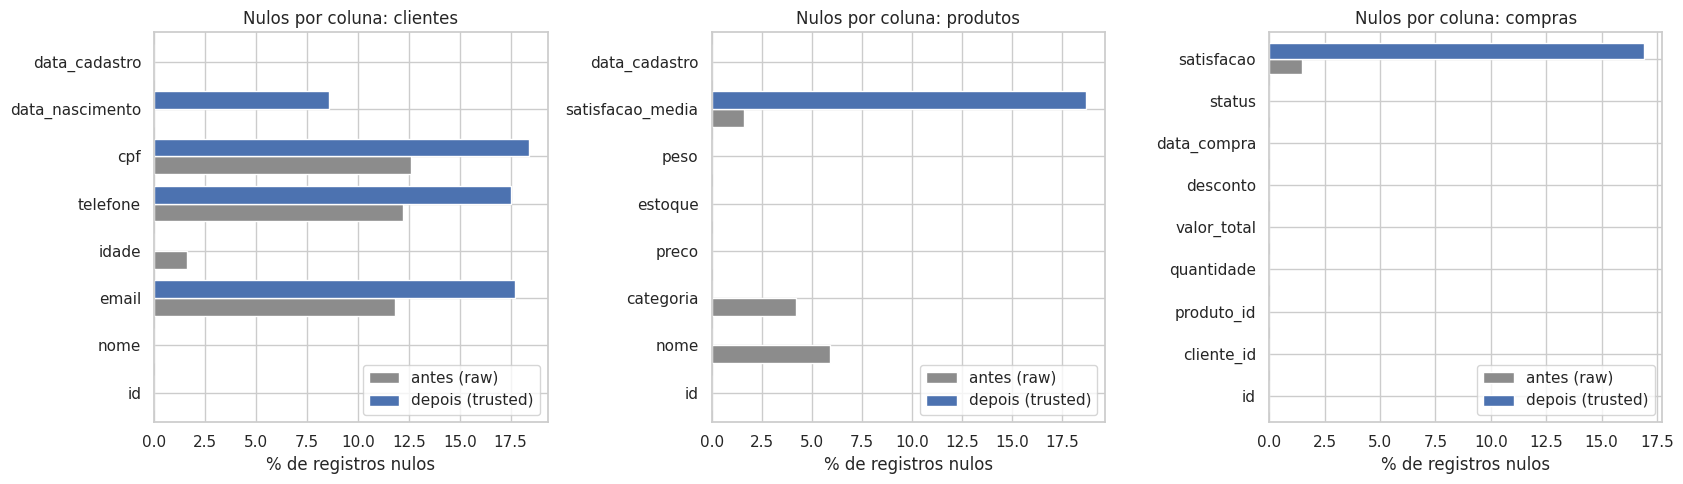

clientes: maior aumento de nulos em 'data_nascimento' (0.0% -> 8.6%). Aumentos vêm de valores inválidos anulados; quedas vêm de registros com nulos que foram para a quarentena.
produtos: maior aumento de nulos em 'satisfacao_media' (1.6% -> 18.7%). Aumentos vêm de valores inválidos anulados; quedas vêm de registros com nulos que foram para a quarentena.
compras: maior aumento de nulos em 'satisfacao' (1.5% -> 16.9%). Aumentos vêm de valores inválidos anulados; quedas vêm de registros com nulos que foram para a quarentena.


In [11]:
# 5.1 Nulos por coluna: antes vs depois
nulos_depois = {t: (trusted[t][nulos_antes[t].index].isna().mean() * 100).round(1) for t in TABELAS}

fig, eixos = plt.subplots(1, 3, figsize=(17, 5))
for ax, t in zip(eixos, TABELAS):
    comp = pd.DataFrame({"antes (raw)": nulos_antes[t], "depois (trusted)": nulos_depois[t]})
    comp.plot.barh(ax=ax, color=["#8C8C8C", "#4C72B0"], width=0.75)
    ax.set_title(f"Nulos por coluna: {t}")
    ax.set_xlabel("% de registros nulos")
    ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

# frase de interpretação gerada a partir dos números
for t in TABELAS:
    delta = (nulos_depois[t] - nulos_antes[t]).sort_values()
    maior = delta.index[-1]
    print(f"{t}: maior aumento de nulos em '{maior}' ({nulos_antes[t][maior]}% -> {nulos_depois[t][maior]}%). "
          "Aumentos vêm de valores inválidos anulados; quedas vêm de registros com nulos que foram para a quarentena.")

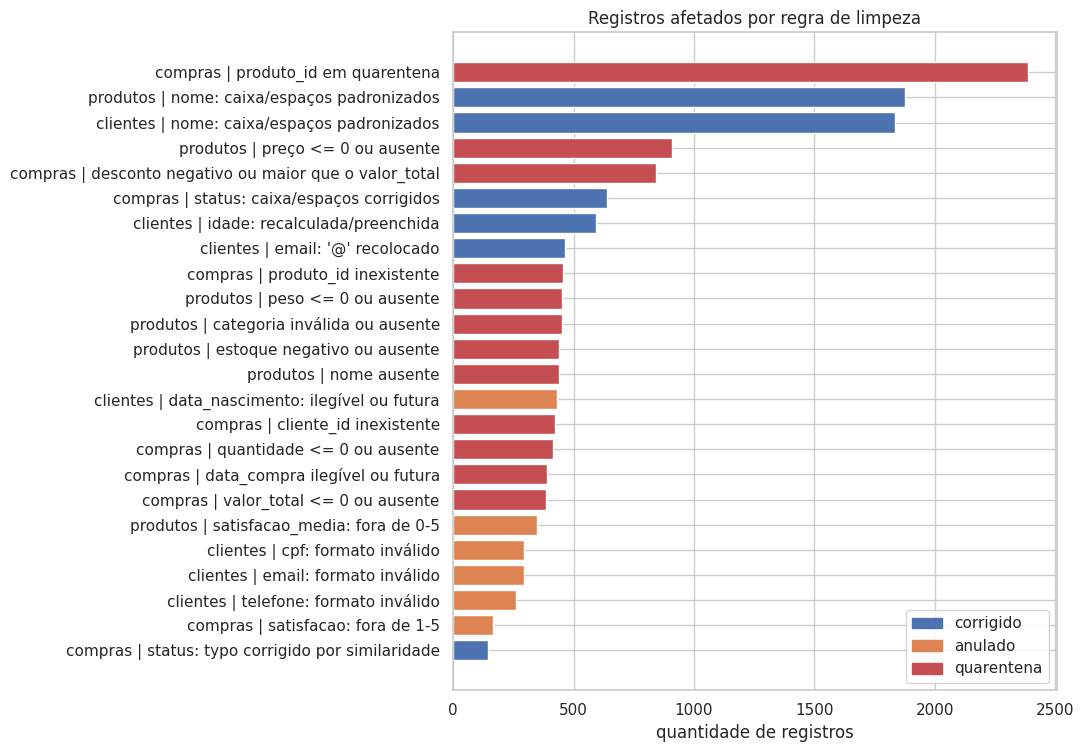

Regra com mais registros afetados: 'produto_id em quarentena' (compras), 2386 registros (quarentena).


In [12]:
# 5.2 Ações por regra (corrigido / anulado / quarentena)
cores_acao = {"corrigido": "#4C72B0", "anulado": "#DD8452", "quarentena": "#C44E52"}
g = rel.assign(rotulo=rel["tabela"] + " | " + rel["regra"]).sort_values("qtd")

fig, ax = plt.subplots(figsize=(11, max(5, 0.32 * len(g))))
ax.barh(g["rotulo"], g["qtd"], color=g["acao"].map(cores_acao))
ax.set_title("Registros afetados por regra de limpeza")
ax.set_xlabel("quantidade de registros")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in cores_acao.values()]
ax.legend(handles, cores_acao.keys(), loc="lower right")
plt.tight_layout()
plt.show()

top = g.iloc[-1]
print(f"Regra com mais registros afetados: '{top['regra']}' ({top['tabela']}), {top['qtd']} registros ({top['acao']}).")

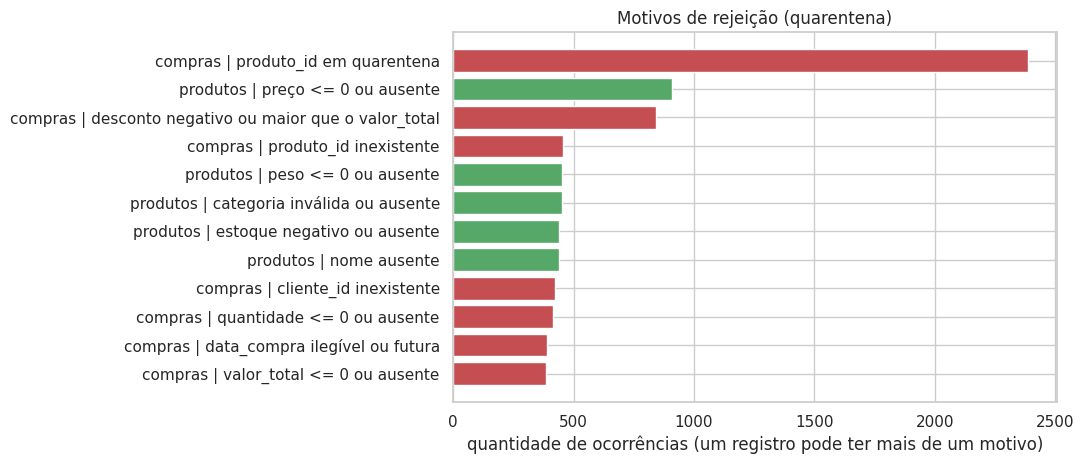

produtos: 2695 de 5000 registros (53.9%) foram para a quarentena.
compras: 3816 de 5000 registros (76.3%) foram para a quarentena.


In [13]:
# 5.3 Motivos de rejeição na quarentena
motivos = rel[rel["acao"] == "quarentena"].assign(rotulo=lambda d: d["tabela"] + " | " + d["regra"]).sort_values("qtd")
cores_tabela = {"produtos": "#55A868", "compras": "#C44E52", "clientes": "#4C72B0"}

fig, ax = plt.subplots(figsize=(11, max(4, 0.4 * len(motivos))))
ax.barh(motivos["rotulo"], motivos["qtd"], color=motivos["tabela"].map(cores_tabela))
ax.set_title("Motivos de rejeição (quarentena)")
ax.set_xlabel("quantidade de ocorrências (um registro pode ter mais de um motivo)")
plt.tight_layout()
plt.show()

for t in ["produtos", "compras"]:
    q = len(quarentena[t])
    print(f"{t}: {q} de {len(raw[t])} registros ({100 * q / len(raw[t]):.1f}%) foram para a quarentena.")

## 6. Gráficos da EDA (dados trusted)

Distribuições depois da limpeza. Cada gráfico tem uma frase de interpretação gerada a partir dos próprios números.

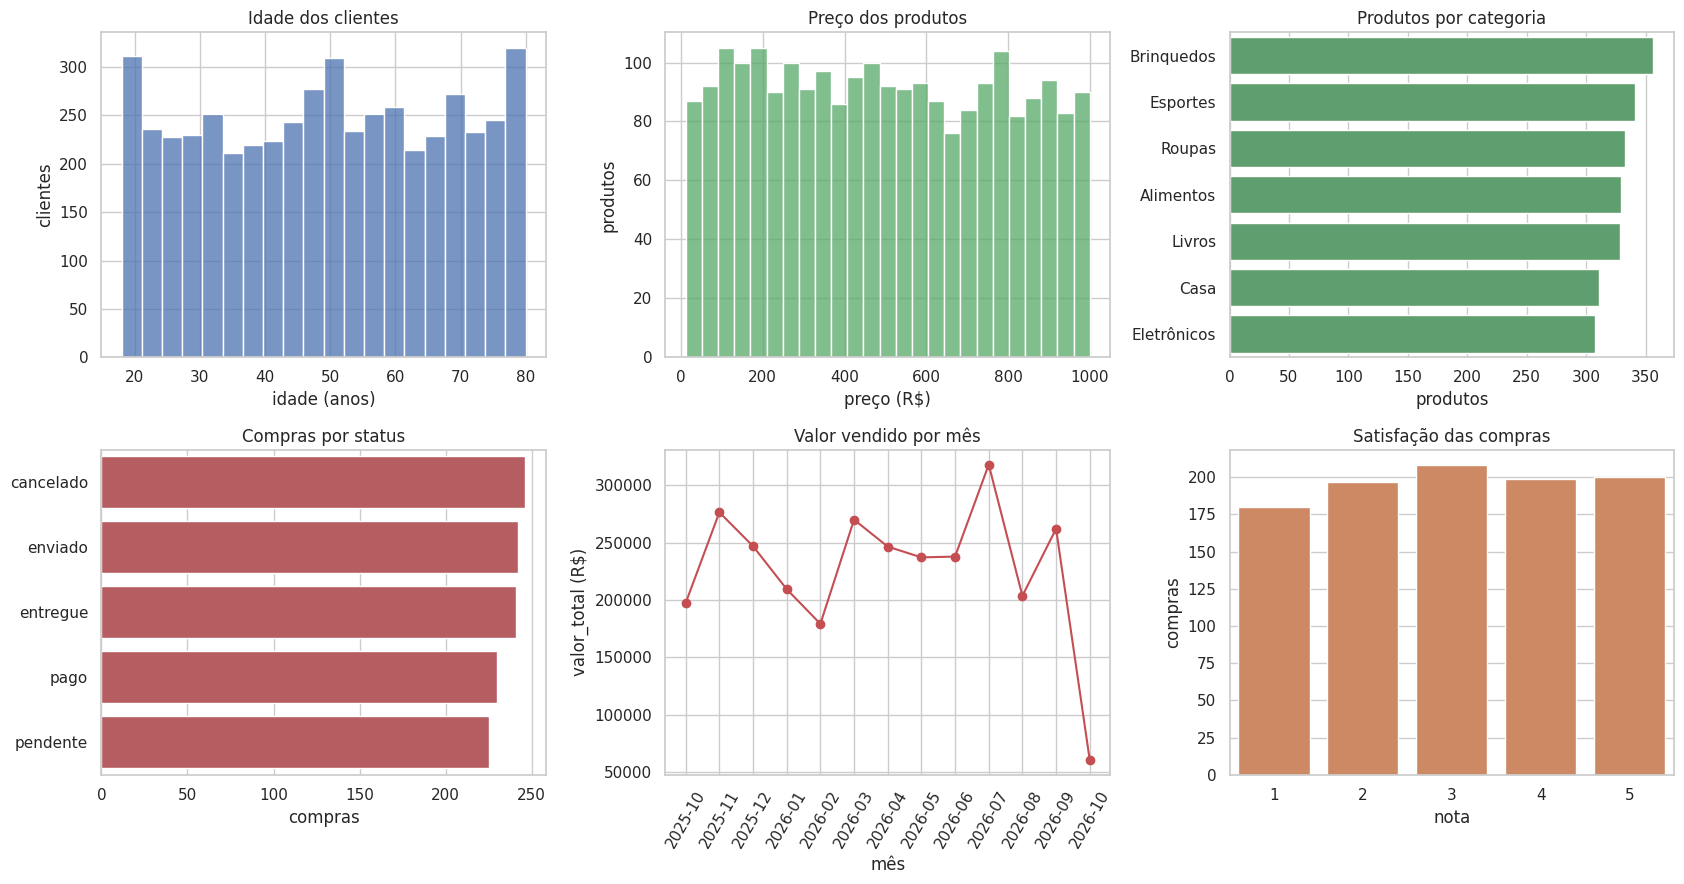

Idade: mediana de 49 anos, de 18 a 80.
Preço: mediana de R$ 487.45, de R$ 11.39 a R$ 999.97.
Categoria com mais produtos: Brinquedos.
Status mais frequente: cancelado.
Mês com mais vendas: 2026-07 (R$ 318,207.37).
Satisfação: nota mais comum 3; 16.9% sem nota.


In [14]:
fig, eixos = plt.subplots(2, 3, figsize=(17, 9))

sns.histplot(clientes_ok["idade"].dropna().astype(int), bins=20, color="#4C72B0", ax=eixos[0, 0])
eixos[0, 0].set(title="Idade dos clientes", xlabel="idade (anos)", ylabel="clientes")

sns.histplot(produtos_ok["preco"], bins=25, color="#55A868", ax=eixos[0, 1])
eixos[0, 1].set(title="Preço dos produtos", xlabel="preço (R$)", ylabel="produtos")

ordem = produtos_ok["categoria"].value_counts()
sns.barplot(x=ordem.values, y=ordem.index, color="#55A868", ax=eixos[0, 2])
eixos[0, 2].set(title="Produtos por categoria", xlabel="produtos", ylabel="")

ordem = compras_ok["status"].value_counts()
sns.barplot(x=ordem.values, y=ordem.index, color="#C44E52", ax=eixos[1, 0])
eixos[1, 0].set(title="Compras por status", xlabel="compras", ylabel="")

por_mes = compras_ok.groupby(compras_ok["data_compra"].dt.to_period("M"))["valor_total"].sum()
eixos[1, 1].plot(por_mes.index.astype(str), por_mes.values, marker="o", color="#C44E52")
eixos[1, 1].set(title="Valor vendido por mês", xlabel="mês", ylabel="valor_total (R$)")
eixos[1, 1].tick_params(axis="x", rotation=60)

sns.countplot(x=compras_ok["satisfacao"].dropna().astype(int), color="#DD8452", ax=eixos[1, 2])
eixos[1, 2].set(title="Satisfação das compras", xlabel="nota", ylabel="compras")

plt.tight_layout()
plt.show()

print(f"Idade: mediana de {clientes_ok['idade'].median():.0f} anos, de {clientes_ok['idade'].min()} a {clientes_ok['idade'].max()}.")
print(f"Preço: mediana de R$ {produtos_ok['preco'].median():.2f}, de R$ {produtos_ok['preco'].min():.2f} a R$ {produtos_ok['preco'].max():.2f}.")
print(f"Categoria com mais produtos: {produtos_ok['categoria'].value_counts().idxmax()}.")
print(f"Status mais frequente: {compras_ok['status'].value_counts().idxmax()}.")
print(f"Mês com mais vendas: {por_mes.idxmax()} (R$ {por_mes.max():,.2f}).")
print(f"Satisfação: nota mais comum {compras_ok['satisfacao'].mode().iloc[0]}; {compras_ok['satisfacao'].isna().mean() * 100:.1f}% sem nota.")

## 7. Interpretação (por IA)

A célula abaixo manda **só números agregados** (o resumo e o relatório de qualidade, nunca registros de clientes) para o Gemini e mostra a interpretação.

Para usar: crie uma chave em [aistudio.google.com](https://aistudio.google.com) e salve nos *Secrets* do Colab (ícone de chave) com o nome `GEMINI_API_KEY`, com "Acesso ao notebook" ligado. Sem a chave, a célula só avisa e o resto do notebook funciona normalmente.

> Leia o texto gerado antes de confiar nele. Para fixar uma versão no repositório, copie-o para uma célula de texto.

In [15]:
%pip install -q google-genai

from IPython.display import Markdown

try:
    from google.colab import userdata
    CHAVE = userdata.get("GEMINI_API_KEY")
except ImportError:                      # fora do Colab: usa variável de ambiente
    CHAVE = os.environ.get("GEMINI_API_KEY")
except Exception as e:                  # Secret inexistente ou sem "Acesso ao notebook"
    print("Não consegui ler o Secret:", type(e).__name__)
    CHAVE = None

if not CHAVE:
    print("Sem GEMINI_API_KEY: pulando a interpretação por IA.")
else:
    try:
        from google import genai

        prompt = f'''Você é um analista de dados sênior revisando a limpeza de um projeto de Data Warehouse (loja de roupas, dados simulados).
Com base APENAS nos números abaixo, escreva em português, em 3 parágrafos curtos:
1) o que a limpeza revelou sobre a qualidade dos dados brutos (quais problemas dominam);
2) o impacto na quantidade de dados aproveitáveis (trusted vs quarentena) e se isso é preocupante;
3) recomendações para melhorar a origem dos dados (cadastro, gerador, validações).
Não invente números que não estejam nos dados.

RESUMO POR TABELA:
{resumo.to_string(index=False)}

REGRAS APLICADAS (tabela, regra, ação, quantidade):
{rel.sort_values(["tabela", "acao", "qtd"], ascending=[True, True, False]).to_string(index=False)}
'''
        client = genai.Client(api_key=CHAVE)
        resp = client.models.generate_content(model="gemini-3.8-flash", contents=prompt)
        display(Markdown("### Interpretação (gerada por IA)\n\n" + resp.text))
    except Exception as e:
        print("A chamada à IA falhou:", type(e).__name__, "-", str(e)[:300])

### Interpretação (gerada por IA)

A limpeza revelou falhas estruturais graves e problemas de integridade referencial nos dados brutos. Embora a base de clientes tenha concentrado problemas de formatação e preenchimento corrigidos ou anulados (como 1.836 nomes padronizados, 432 datas de nascimento inválidas e 294 CPFs inválidos), as tabelas de produtos e compras apresentaram violações severas de regras de negócio. Em produtos, predominam campos vitais ausentes ou negativos, liderados por preço (910 casos), peso (453), categoria (451) e estoque (441). Em compras, o maior problema foi o efeito cascata de chaves dependentes de `produto_id em quarentena` (2.386 ocorrências), além de inconsistências financeiras graves como desconto negativo ou superior ao total (844 ocorrências) e ausência de chaves válidas (457 produtos e 423 clientes inexistentes).

O impacto no volume de dados aproveitáveis é crítico e altamente preocupante. Enquanto clientes manteve 100% de aproveitamento (5.000 linhas *trusted* e 0 em quarentena), produtos reteve apenas 46,1% (2.305 *trusted* contra 2.695 em quarentena) e compras teve um aproveitamento de meros 23,7% (1.184 *trusted* e 3.816 em quarentena). Esse cenário compromete severamente as análises de negócio no Data Warehouse, já que mais de 76% das transações foram descartadas, grande parte contaminada pela própria rejeição prévia no cadastro de produtos.

Para sanar a origem (seja no gerador ou sistema de cadastro), recomenda-se instituir validações rígidas de integridade referencial que impeçam compras com `cliente_id` ou `produto_id` inexistentes. Além disso, devem ser aplicadas travas de formulário contra valores nulos ou menores/iguais a zero para preço, peso, estoque, quantidade e valor total, além de validação lógica impedindo descontos negativos ou maiores que o total (responsáveis por 844 falhas). Por fim, o cadastro precisa de máscaras e regras de formato para CPFs, e-mails, telefones e bloqueio de datas futuras (presentes em 432 clientes e 390 compras).

## 8. Salvar `trusted` e `quarentena`

Antes de salvar, o notebook confere as garantias que a Etapa 4 (Data Warehouse) assume.

In [16]:
# ---- verificações ----
for t in TABELAS:
    assert "inconsistente" not in trusted[t].columns, f"{t}: coluna 'inconsistente' ainda presente"
    assert trusted[t]["id"].is_unique, f"{t}: ids duplicados na trusted"
for t in ["produtos", "compras"]:
    assert (quarentena[t]["motivo_rejeicao"].str.len() > 0).all(), f"{t}: quarentena sem motivo_rejeicao"
    assert len(trusted[t]) + len(quarentena[t]) == len(raw[t]), f"{t}: linhas perdidas"
assert compras_ok["cliente_id"].isin(clientes_ok["id"]).all(), "compras com cliente inexistente na trusted"
assert compras_ok["produto_id"].isin(produtos_ok["id"]).all(), "compras com produto inexistente na trusted"
assert (compras_ok["quantidade"] > 0).all() and (compras_ok["valor_total"] > 0).all()
assert (compras_ok["desconto"] <= compras_ok["valor_total"]).all()
assert compras_ok["status"].isin(STATUS_VALIDOS).all()
print("Todas as verificações passaram.")

# ---- salvar ----
os.makedirs(SAIDA, exist_ok=True)
saidas = {
    f"trusted_clientes_{LOTE}.csv": clientes_ok,
    f"trusted_produtos_{LOTE}.csv": produtos_ok,
    f"trusted_compras_{LOTE}.csv": compras_ok,
    f"quarentena_produtos_{LOTE}.csv": produtos_quarentena,
    f"quarentena_compras_{LOTE}.csv": compras_quarentena,
    f"relatorio_qualidade_{LOTE}.csv": rel,
}
for nome, df in saidas.items():
    df.to_csv(f"{SAIDA}/{nome}", index=False)
    print(f"{SAIDA}/{nome:35s} {len(df):>6} linhas")

if BAIXAR_ZIP:
    try:
        from google.colab import files
        shutil.make_archive("saida_etapa3", "zip", SAIDA)
        files.download("saida_etapa3.zip")
    except ImportError:
        print("Fora do Colab: os arquivos estão na pasta", SAIDA)

Todas as verificações passaram.
saida/trusted_clientes_1.csv                5000 linhas
saida/trusted_produtos_1.csv                2305 linhas
saida/trusted_compras_1.csv                 1184 linhas
saida/quarentena_produtos_1.csv             2695 linhas
saida/quarentena_compras_1.csv              3816 linhas
saida/relatorio_qualidade_1.csv               24 linhas


## Próximos passos

**Etapa 4: Data Warehouse (esquema estrela).** Ler os `trusted_*.csv`, criar as chaves compostas (`lote` + `id`) antes de qualquer join, montar `dim_cliente`, `dim_produto`, `dim_data` e `fato_vendas`.

Checklist antes do commit:

- [ ] o notebook roda do início ao fim sem depender de arquivos fora do repositório;
- [ ] a coluna `inconsistente` não existe nas saídas;
- [ ] todos os registros da quarentena têm `motivo_rejeicao`;
- [ ] os gráficos têm título, eixos rotulados e uma frase de interpretação.